# 12 · Time weighting (work package 4, core problem 2)

**Work package 4** of the [implementation plan](../../research/implementation_plan.md). How much should an old
trade count against a recent one, and how much history is worth keeping?

An account's trade of a token gets the weight

$$\omega_{ui} = 2^{-a/h}$$

where $a$ is the age in days of the account's **last** trade of the token at the evaluation point $t$, and $h$ is
the half-life: a trade $h$ days old counts half as much as one made just now. Only trades of the last $L$ days are
kept. The same weights enter all three places of the fixed combination of notebook 11:

| Place | Formula |
| --- | --- |
| Popularity | $p_i = \sum_u \omega_{ui}$ |
| Similarity | the shrunk cosine of the weighted account-token matrix |
| Account profile | $r_{ui} = \sum_{j \in H_u} \omega_{uj}\, s_{ji}$ |

With $h = \infty$ and $L = 14$ days this is exactly the model of notebook 11.

**Procedure.** $k$ and $\lambda$ are those chosen in notebook 11. $h$, $L$ and the weight $w$ are chosen on Dev A,
and the chosen model is compared on Dev B with the baseline and with the untimed blend of notebook 11.

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import pool_recsys as pr
import protocol as pc
import stats
import token_data as td
import tuning

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = pc.RESULTS_DIR / "wp4"
OUT.mkdir(parents=True, exist_ok=True)
CONFIGS = pc.RESULTS_DIR.parent / "configs"

legs = td.load_legs()
wp3 = json.loads((CONFIGS / "wp3_knn.json").read_text())
print("From notebook 11:", wp3)

From notebook 11: {'k': 400, 'shrink': 200.0, 'weight': 0.5, 'chosen_on': 'dev_a', 'mean_recall_dev_a': 0.2017}


## 1. The grid, evaluated on Dev A

| Setting | Values |
| --- | --- |
| $h$, half-life in days | 0.5, 1, 2, 4, 7, 14, ∞ |
| $L$, history length in days | 7, 14, 28, all (since 18 June) |
| $w$, weight of popularity | 0, 0.1, …, 1.0 |

**A limit of Dev A (implementation plan, open point 11.1).** The first Dev A point has only 14 days of data behind
it, the last one 32. So $L = 28$ and $L$ = all are the same as $L = 14$ at the first point and differ only at the
later ones. The effect of $L$ is therefore also shown on Dev B (section 4), where every point has at least 34 days.

In [2]:
HALF_LIVES = [0.5, 1, 2, 4, 7, 14, None]  # None = no decay
LENGTHS = [7, 14, 28, None]  # None = all data since 18 June
WEIGHTS = [round(0.1 * i, 1) for i in range(11)]
GRID_DIR = OUT / "grid_dev_a"  # one file per point, so a stopped run resumes
GRID_DIR.mkdir(exist_ok=True)


def grid_for_point(t: pd.Timestamp) -> pd.DataFrame:
    """Every (h, L, w) setting at one Dev A point, read from disk if already computed."""
    point_file = GRID_DIR / f"{t:%Y-%m-%d}.csv"
    if point_file.exists():
        return pd.read_csv(point_file, parse_dates=["point"])
    task = pc.load_task(legs, t)
    parts = []
    for length in LENGTHS:
        ages = task.history_ages(length)
        for half_life in HALF_LIVES:
            weighted = pr.time_weights(ages, half_life)
            part = tuning.blend_grid(task, weighted, weighted, [wp3["k"]], [wp3["shrink"]], WEIGHTS)
            parts.append(part.assign(
                half_life=half_life if half_life else float("inf"),
                history_days=length if length else float("inf"),
            ))
    result = pd.concat(parts, ignore_index=True)
    result.to_csv(point_file, index=False)
    print(f"  {t:%d %b}: done ({len(task.eval_rows):,} accounts)", flush=True)
    return result


grid = pd.concat([grid_for_point(t) for t in pc.POINTS["dev_a"]], ignore_index=True)
print(f"Grid: {len(grid):,} rows")

Grid: 3,080 rows


Mean recall@10 over Dev A, at the best weight $w$ of each ($h$, $L$). Rows: half-life; columns: history length.

In [3]:
mean = grid.groupby(["half_life", "history_days", "weight"], as_index=False)["recall"].mean()
best_per_cell = mean.loc[mean.groupby(["half_life", "history_days"])["recall"].idxmax()]
best_per_cell.pivot(index="half_life", columns="history_days", values="recall")

history_days,7.0000,14.0000,28.0000,inf
half_life,,,,
0.5000,0.1735,0.1797,0.1798,0.1798
1.0000,0.1829,0.1915,0.1918,0.1918
2.0000,0.1952,0.2042,0.2063,0.2063
4.0000,0.1957,0.2091,0.2116,0.2117
7.0000,0.1946,0.2083,0.2121,0.2122
14.0000,0.1924,0.2063,0.2089,0.2092
inf,0.1896,0.2031,0.2002,0.2004


The same table as a chart: recall over the half-life, one line per history length.

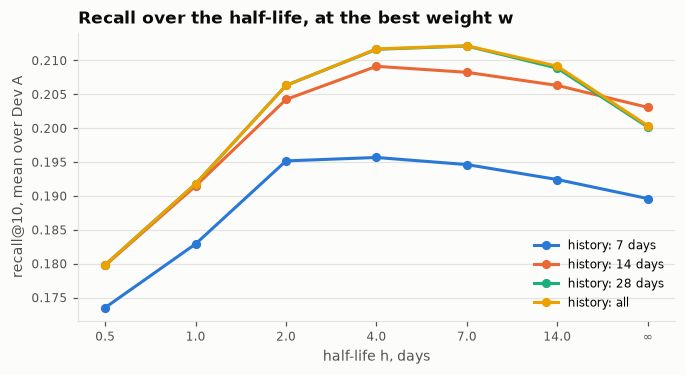

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
labels = {7.0: "7 days", 14.0: "14 days", 28.0: "28 days", float("inf"): "all"}
for slot, (length, part) in enumerate(best_per_cell.groupby("history_days")):
    x = [str(h if h != float("inf") else "∞") for h in part["half_life"]]
    ax.plot(x, part["recall"], marker="o", color=plots.SERIES[slot], label=f"history: {labels[length]}")
ax.set_xlabel("half-life h, days")
ax.set_ylabel("recall@10, mean over Dev A")
ax.set_title("Recall over the half-life, at the best weight w")
ax.legend(loc="lower right")
plt.show()

## 2. The choice

The rule of the implementation plan: the highest mean recall on Dev A; among settings within 0.002 of it, the
simpler one, here: the longer half-life (less decay), then the longer history, then more weight on popularity.

In [5]:
chosen = tuning.best_setting(
    grid, ["half_life", "history_days", "weight"], {"half_life": "large", "history_days": "large", "weight": "large"}
)


def to_setting(value):
    """Infinity in the grid table means "no decay" or "all history", which the code writes as None."""
    return None if value == float("inf") else float(value)


settings = {
    "k": wp3["k"],
    "shrink": wp3["shrink"],
    "weight": float(chosen["weight"]),
    "half_life": to_setting(chosen["half_life"]),
    "history_days": to_setting(chosen["history_days"]),
}
(CONFIGS / "wp4_time.json").write_text(
    json.dumps({**settings, "chosen_on": "dev_a", "mean_recall_dev_a": round(float(chosen["recall"]), 4)}, indent=2)
)
print(f"Chosen on Dev A: {settings}, mean recall {chosen['recall']:.4f}")

Chosen on Dev A: {'k': 400, 'shrink': 200.0, 'weight': 0.2, 'half_life': 7.0, 'history_days': None}, mean recall 0.2122


## 3. Dev B: the time-weighted blend against the baseline and the untimed blend

Also shown, as the two ends of the half-life range: popularity of the last day only (notebook 10) and popularity
of all data since 18 June ($h = \infty$, $L$ = all).

In [6]:
DEV_B = pc.POINTS["dev_b"]


def read(path):
    """A per-point result table saved by an earlier notebook."""
    return pd.read_csv(path, parse_dates=["point"])


baseline_b = read(pc.RESULTS_DIR / "wp2" / "baseline_dev.csv").query("part == 'dev_b'")
recent_b = read(pc.RESULTS_DIR / "wp2" / "recent_popularity_dev.csv").query("part == 'dev_b'")
blend_b = read(pc.RESULTS_DIR / "wp3" / "fixed_blend_dev_b.csv")

timed = pc.run("time-weighted blend", lambda task: tuning.fixed_blend_scorer(task, settings), legs, DEV_B, verbose=False)
all_time = pc.run("all-time popularity", lambda task: pc.popularity_scorer(task, days=None), legs, DEV_B, verbose=False)
timed.per_point.to_csv(OUT / "time_weighted_blend_dev_b.csv", index=False)
all_time.per_point.to_csv(OUT / "all_time_popularity_dev_b.csv", index=False)

results = {
    "popularity (baseline)": baseline_b,
    "fixed blend": blend_b,
    "time-weighted blend": timed.per_point,
    "recent popularity": recent_b,
    "all-time popularity": all_time.per_point,
}
comparison = stats.compare(results, baseline="popularity (baseline)")
comparison.to_csv(OUT / "compare_dev_b.csv", index=False)
comparison

,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
0,popularity (baseline),11,0.0936,0.0773,0.1053,NaN,NaN,NaN,NaN,NaN
1,fixed blend,11,0.1422,0.1219,0.1561,0.0486,0.0446,0.0523,11 of 11,0.0010
2,time-weighted blend,11,0.1426,0.1240,0.1570,0.0491,0.0441,0.0535,11 of 11,0.0010
3,recent popularity,11,0.1048,0.0807,0.1269,0.0112,0.0046,0.0190,9 of 11,0.0654
4,all-time popularity,11,0.0694,0.0499,0.0817,-0.0242,-0.0277,-0.0206,0 of 11,0.0010


The gain from time weighting alone: the time-weighted blend against the untimed blend of notebook 11, point by point.

In [7]:
d = stats.paired_differences(timed.per_point, blend_b)
low, high = stats.bootstrap_over_points(d)
signs = stats.sign_test(d)
print(f"time-weighted minus untimed blend on Dev B: mean {d.mean():+.4f}, 95% interval [{low:+.4f}, {high:+.4f}], "
      f"wins {signs['wins']} of {len(d)}")  # fmt: skip

time-weighted minus untimed blend on Dev B: mean +0.0004, 95% interval [-0.0019, +0.0028], wins 5 of 11


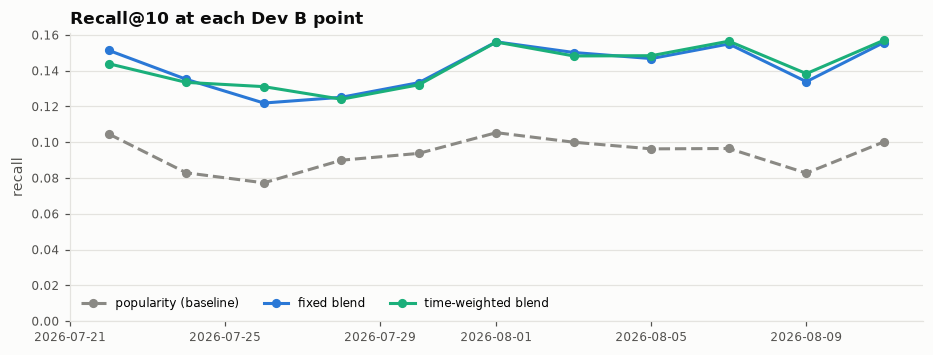

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.per_point_lines(ax, {k: results[k] for k in ["popularity (baseline)", "fixed blend", "time-weighted blend"]})
ax.set_title("Recall@10 at each Dev B point")
plt.show()

## 4. The effect of the history length, on Dev B

Because of the limit described in section 1, the chosen half-life is also run on Dev B with each history length.
This is reported, not used for any choice.

In [9]:
by_length = {}
for length in LENGTHS:
    variant = {**settings, "history_days": length}
    name = f"L = {length if length else 'all'}"
    by_length[name] = pc.run(name, lambda task: tuning.fixed_blend_scorer(task, variant), legs, DEV_B, verbose=False).per_point
length_table = pd.DataFrame({name: table[["recall", "recall_1", "recall_2-4", "recall_5+"]].mean() for name, table in by_length.items()}).T
length_table.to_csv(OUT / "history_length_dev_b.csv")
length_table

,recall,recall_1,recall_2-4,recall_5+
L = 7,0.1319,0.1796,0.1474,0.0965
L = 14,0.1406,0.2018,0.1546,0.0986
L = 28,0.1421,0.2049,0.1564,0.0990
L = all,0.1426,0.2059,0.1573,0.0991


## 5. Reading

- **On Dev A, time weighting helps.** The best setting ($h$ = 7 days, all history, $w$ = 0.2) reaches recall 0.212
  against 0.202 without decay on 14 days (notebook 11). Recall rises from $h$ = 0.5 to 4–7 days and falls again
  towards no decay; a history longer than 14 days helps only together with decay.
- **On Dev B the gain disappears.** The time-weighted blend scores 0.1426, the untimed blend 0.1422: a difference of
  +0.0004 with a 95% interval of −0.002 to +0.003, and 5 wins of 11. Time weighting does not reliably improve the
  model, so the untimed blend of notebook 11 is as good on unseen points and simpler.
- **Why Dev A and Dev B disagree** is not settled here. One candidate is the groups of identical accounts of
  notebook 11 (section 2b), which are more frequent on Dev A: a farm that traded a token a few days before $t$ is
  exactly what decay up-weights.
- **Popularity alone does depend on time:** popularity of the last day beats the 14-day baseline on Dev B
  (+0.011, 9 of 11), and popularity of all data since 18 June is worse at every point (−0.024, 0 of 11). Once
  neighbours are added, this advantage of recent data is no longer visible.
- **History length on Dev B** (section 4, chosen $h$): 7 days is clearly worse (0.132); 14, 28 days and all data
  are within 0.002 of each other.

The chosen setting is written to `configs/wp4_time.json` as the rule requires. Which of the two blends goes into
the ranker and the frozen comparison is decided on Dev B in WP6/WP7 (implementation plan, 9.1).